Procesando texto con SpaCy...
Total de oraciones procesadas: 36
Ejemplo (tokens): ['cerebro', 'dinosaurio']
Texto procesado guardado correctamente.

Entrenando red neuronal Word2Vec...

Palabras más cercanas semánticamente a 'cerebro':
  - prehistórica (Similitud: 0.8355)
  - programa (Similitud: 0.6880)
  - ocasión (Similitud: 0.6767)

Palabras más cercanas semánticamente a 'trabajo':
  - defensa (Similitud: 0.7673)
  - vida (Similitud: 0.6949)
  - defender (Similitud: 0.6363)

Palabras más cercanas semánticamente a 'enojo':
  - 3 (Similitud: 0.7484)
  - apagafuego (Similitud: 0.7183)
  - seguir (Similitud: 0.6614)


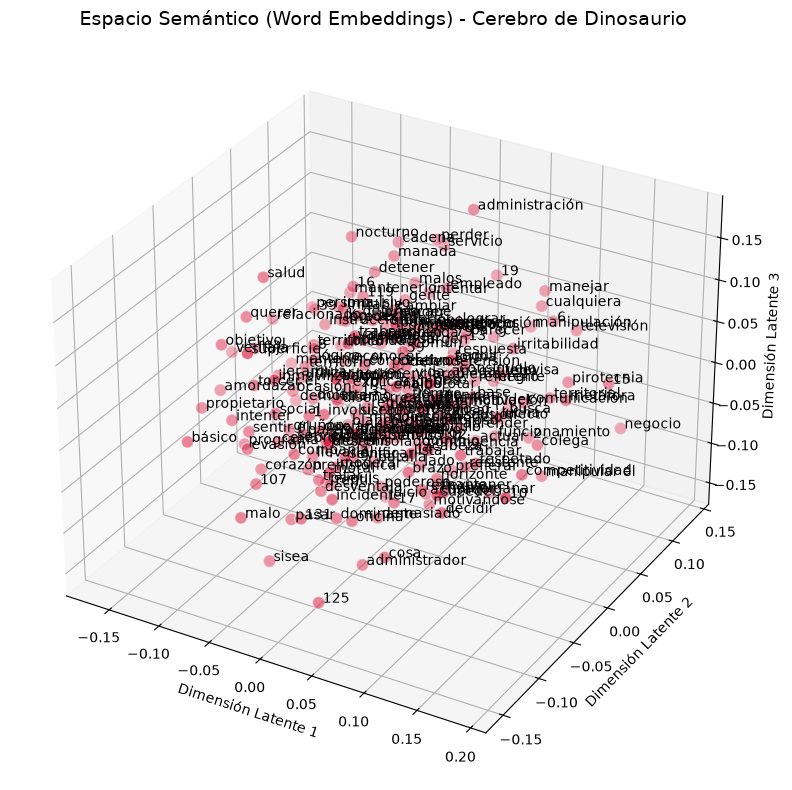

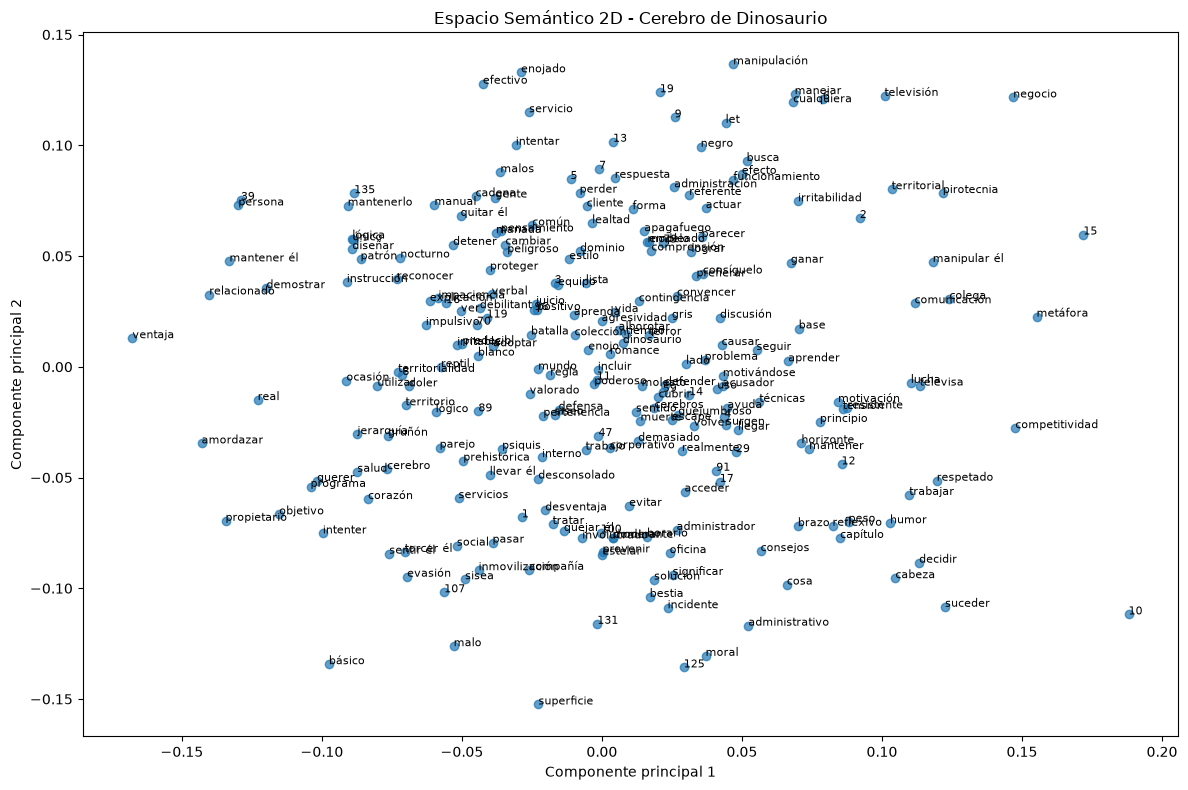


Vector de la palabra 'cerebro':
[ 0.00010862 -0.02561134 -0.06402169  0.08633804  0.05715755  0.02842645
 -0.01946473  0.06404221  0.00884642 -0.01121974]


In [1]:
import pandas as pd
import spacy
from gensim.models import Word2Vec
import multiprocessing
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import numpy as np

# 1. PREPARACIÓN DE DATOS
nlp = spacy.load("es_core_news_sm")

with open("dino.txt", "r", encoding="utf-8") as f:
    texto_dinosaurio = f.read()


print("Procesando texto con SpaCy...")
doc = nlp(texto_dinosaurio)

sentences = []
for sent in doc.sents:
    # Lematizamos y quitamos stop words para reducir ruido
    tokens = [
        token.lemma_.lower() 
        for token in sent 
        if not token.is_stop and not token.is_punct and token.text.strip()
    ]
    if len(tokens) > 1: # Solo oraciones con algo de contenido
        sentences.append(tokens)

print(f"Total de oraciones procesadas: {len(sentences)}")

if sentences:
    print(f"Ejemplo (tokens): {sentences[0]}")
else:
    raise ValueError("No se encontraron oraciones con suficientes palabras.")

# Guardamos el texto después de limpiarlo y lematizarlo
with open("texto_procesado.txt", "w", encoding="utf-8") as f:
    for sentence in sentences:
        f.write(" ".join(sentence) + "\n")

print("Texto procesado guardado correctamente.")

# 2. ENTRENAMIENTO DE WORD2VEC
# Creamos vectores densos (Embeddings)
print("\nEntrenando red neuronal Word2Vec...")

model = Word2Vec(
    sentences,
    vector_size=10,  # 10 dimensiones (neuronas en la capa oculta)
    window=5,        # Contexto
    min_count=1,     # Aceptamos palabras únicas por ser un dataset mini
    workers=multiprocessing.cpu_count(),
    seed=42          # Semilla para reproducibilidad
)

# 3. EXPLORACIÓN SEMÁNTICA
def mostrar_similares(palabra):
    try:
        # topn=3 nos da las 3 palabras más cercanas en el espacio vectorial
        similares = model.wv.most_similar(palabra, topn=3)
        print(f"\nPalabras más cercanas semánticamente a '{palabra}':")
        for sim in similares:
            # sim es una tupla (palabra, puntuación)
            print(f"  - {sim[0]} (Similitud: {sim[1]:.4f})")
    except KeyError:
        print(f"\nLa palabra '{palabra}' no está en el vocabulario.")

# Probamos conceptos (Nota: con texto tan corto, las asociaciones serán raras)
mostrar_similares("cerebro")
mostrar_similares("trabajo")
mostrar_similares("enojo")


# 4. VISUALIZACIÓN 3D (PCA de Embeddings)
# Aquí ocurre la magia: proyectamos las 10 dimensiones a 3 para verlas.

# Obtenemos todas las palabras y sus vectores
vocabulario = list(model.wv.index_to_key)
vectores = model.wv[vocabulario]

# Reducción de dimensionalidad
pca = PCA(n_components=3)
vectores_3d = pca.fit_transform(vectores)

# Crear DataFrame para facilitar ploteo
df_3d = pd.DataFrame(vectores_3d, columns=['x', 'y', 'z'])
df_3d['palabra'] = vocabulario

# Gráfico
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
ax.scatter(df_3d['x'], df_3d['y'], df_3d['z'], c='crimson', s=80, edgecolors='white', alpha=0.8)

# Etiquetas
for i, row in df_3d.iterrows():
    ax.text(row['x'], row['y'], row['z'], f" {row['palabra']}", size=10)

ax.set_title('Espacio Semántico (Word Embeddings) - Cerebro de Dinosaurio', fontsize=14)
ax.set_xlabel('Dimensión Latente 1')
ax.set_ylabel('Dimensión Latente 2')
ax.set_zlabel('Dimensión Latente 3')

plt.tight_layout()

# Guardamos la gráfica 3D
plt.savefig("espacio_vectorial_3d.png", dpi=300, bbox_inches="tight")

plt.show()

# 5. VISUALIZACIÓN 2D DEL ESPACIO VECTORIAL

pca_2d = PCA(n_components=2)
vectores_2d = pca_2d.fit_transform(vectores)

plt.figure(figsize=(12, 8))

plt.scatter(
    vectores_2d[:, 0],
    vectores_2d[:, 1],
    alpha=0.7
)

# Mostramos cada palabra junto a su vector
for i, palabra in enumerate(vocabulario):
    plt.annotate(
        palabra,
        (vectores_2d[i, 0], vectores_2d[i, 1]),
        fontsize=8
    )

plt.title("Espacio Semántico 2D - Cerebro de Dinosaurio")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

plt.tight_layout()

# Guardamos la gráfica 2D
plt.savefig("espacio_vectorial_2d.png", dpi=300, bbox_inches="tight")

plt.show()


# Mostramos el vector de una palabra del libro
palabra = "cerebro"

if palabra in model.wv:
    print(f"\nVector de la palabra '{palabra}':")
    print(model.wv[palabra])
else:
    print(f"\nLa palabra '{palabra}' no está en el vocabulario.")